In [ ]:
from typing import Dict, TypedDict
from langgraph.graph import StateGraph

In [22]:
class StateAgent(TypedDict):
    name : str
    age: int
    result: str

def first_process(state: StateAgent):
    state['result'] = f"Hi {state['name']}!"
    return state

def second_process(state: StateAgent):
    state['result'] = f"{state['result']}" + f", Your age is {state['age']}"
    return state


graph = StateGraph(StateAgent)

graph.add_node("first_pass", first_process)
graph.add_node("second_pass", second_process)

graph.set_entry_point("first_pass")
graph.add_edge("first_pass", "second_pass")
graph.set_finish_point("second_pass")

app = graph.compile()


In [23]:
from IPython.display import display, Image

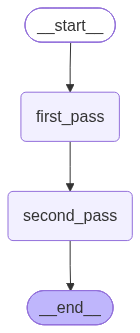

In [24]:
display(Image(app.get_graph().draw_mermaid_png()))

In [25]:
app.invoke({"name":"yaki", "age":10})

{'name': 'yaki', 'age': 10, 'result': 'Hi yaki!, Your age is 10'}